In [1]:
# ==============================================================================
# CELL 1: Load Serialized Counterfactual Bundle & Audit Cohort Rescue Metrics
# ==============================================================================
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import joblib
import warnings
warnings.filterwarnings("ignore")


# Load serialized bundles
cf_bundle = joblib.load("../models/counterfactual_bundle.pkl")
shap_bundle = joblib.load("../models/shap_bundle.pkl")

cf_df = cf_bundle["cf_df"]
lever_summary_df = cf_bundle["lever_summary_df"]
clinical_thresh = cf_bundle["clinical_threshold"]
archetypes = shap_bundle["archetypes"]

rescue_rate = cf_df["Rescued_Below_051"].mean() * 100.0
avg_levers = cf_df.loc[cf_df["Rescued_Below_051"], "Levers_Changed"].mean()

print("=====================================================================")
print("COHORT-WIDE COUNTERFACTUAL INTERVENTION AUDIT")
print("=====================================================================")
print(
    f"High-Risk Holdout Sessions (Prob >= {clinical_thresh:.2f}) : {len(cf_df)}")
print(
    f"Rescued Below {clinical_thresh:.2f} Threshold             : {cf_df['Rescued_Below_051'].sum()}/{len(cf_df)} ({rescue_rate:.2f}%)")
print(
    f"Mean Crash Risk Before Intervention          : {cf_df['Original_Prob'].mean():.2%}")
print(
    f"Mean Crash Risk After Intervention           : {cf_df['Counterfactual_Prob'].mean():.2%}")
print(
    f"Average Absolute Risk Reduction              : -{cf_df['Risk_Reduction'].mean():.2%}")
print(
    f"Average Dials Adjusted (Rescued Cohort)      : {avg_levers:.2f} levers/patient\n")

# Display formatted Bedside Lever Effectiveness Leaderboard
lever_summary_df.style.format({
    "Usage_Rate_Pct": "{:.2f}%",
    "Avg_Risk_Reduction": "{:.4f}",
    "Mean_Setting_Shift": "{:+.4f}",
}).background_gradient(subset=["Times_Prescribed", "Avg_Risk_Reduction"], cmap="YlGnBu")

COHORT-WIDE COUNTERFACTUAL INTERVENTION AUDIT
High-Risk Holdout Sessions (Prob >= 0.51) : 734
Rescued Below 0.51 Threshold             : 381/734 (51.91%)
Mean Crash Risk Before Intervention          : 67.67%
Mean Crash Risk After Intervention           : 55.95%
Average Absolute Risk Reduction              : -11.72%
Average Dials Adjusted (Rescued Cohort)      : 1.41 levers/patient



,Lever_Feature,Display_Name,Times_Prescribed,Usage_Rate_Pct,Avg_Risk_Reduction,Mean_Setting_Shift
0,Dialysate_Temperature,Dialysate Temperature,420,57.22%,0.1366,+0.3781
1,Transmembrane_Pressure,Transmembrane Pressure (TMP),336,45.78%,0.1142,+0.2631
2,Dialysate_Bath,Dialysate Bath Profile,210,28.61%,0.1460,-0.1167
3,Dialysate_Flow,Dialysate Flow Rate,201,27.38%,0.1015,+0.1201
4,Blood_Flow,Blood Flow Rate (Qb),182,24.80%,0.0917,+0.2321
5,Dialysate_Conductivity,Dialysate Conductivity,147,20.03%,0.1019,+0.1156


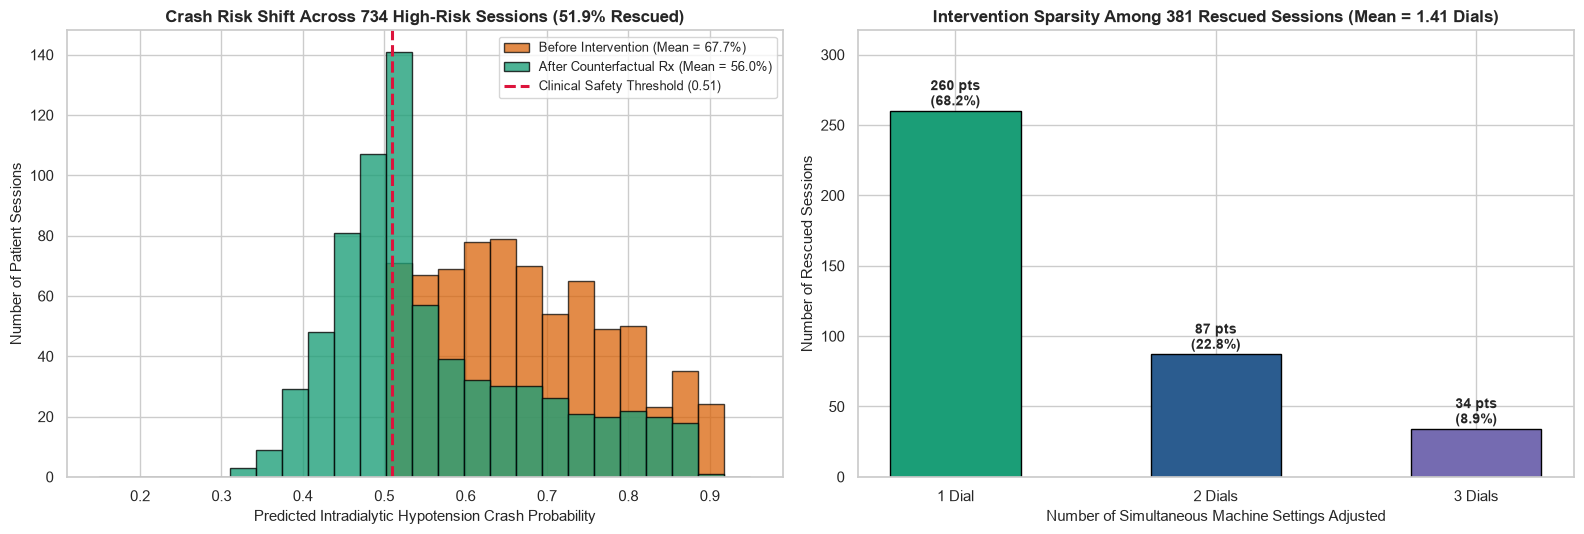

In [2]:
# ==============================================================================
# CELL 2: Risk Reduction Distribution & Intervention Sparsity Breakdown
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Left Panel: Before vs. After Probability Histogram
bins = np.linspace(0.15, 0.95, 26)
axes[0].hist(
    cf_df["Original_Prob"], bins=bins, alpha=0.72, color="#d95f02", edgecolor="black",
    label=f"Before Intervention (Mean = {cf_df['Original_Prob'].mean():.1%})"
)
axes[0].hist(
    cf_df["Counterfactual_Prob"], bins=bins, alpha=0.78, color="#1b9e77", edgecolor="black",
    label=f"After Counterfactual Rx (Mean = {cf_df['Counterfactual_Prob'].mean():.1%})"
)
axes[0].axvline(
    clinical_thresh, color="crimson", linestyle="--", linewidth=2.2,
    label=f"Clinical Safety Threshold ({clinical_thresh:.2f})"
)
axes[0].set_title(
    f"Crash Risk Shift Across {len(cf_df)} High-Risk Sessions ({rescue_rate:.1f}% Rescued)",
    fontsize=12, fontweight="bold"
)
axes[0].set_xlabel(
    "Predicted Intradialytic Hypotension Crash Probability", fontsize=10.5)
axes[0].set_ylabel("Number of Patient Sessions", fontsize=10.5)
axes[0].legend(loc="upper right", fontsize=9)

# Right Panel: Sparsity Breakdown (Number of Machine Dials Adjusted)
rescued_df = cf_df[cf_df["Rescued_Below_051"]]
counts = rescued_df["Levers_Changed"].value_counts().sort_index()
bars = axes[1].bar(
    [f"{int(k)} Dial{'s' if k > 1 else ''}" for k in counts.index],
    counts.values,
    color=["#1b9e77", "#2b5c8f", "#756bb1"][:len(counts)],
    edgecolor="black",
    width=0.5
)
for bar in bars:
    h = bar.get_height()
    pct = (h / len(rescued_df)) * 100.0
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0, h + 4,
        f"{int(h)} pts\n({pct:.1f}%)", ha="center", fontweight="bold", fontsize=10
    )
axes[1].set_ylim(0, counts.max() * 1.22)
axes[1].set_title(
    f"Intervention Sparsity Among {len(rescued_df)} Rescued Sessions (Mean = {avg_levers:.2f} Dials)",
    fontsize=12, fontweight="bold"
)
axes[1].set_xlabel(
    "Number of Simultaneous Machine Settings Adjusted", fontsize=10.5)
axes[1].set_ylabel("Number of Rescued Sessions", fontsize=10.5)

plt.tight_layout()
plt.show()

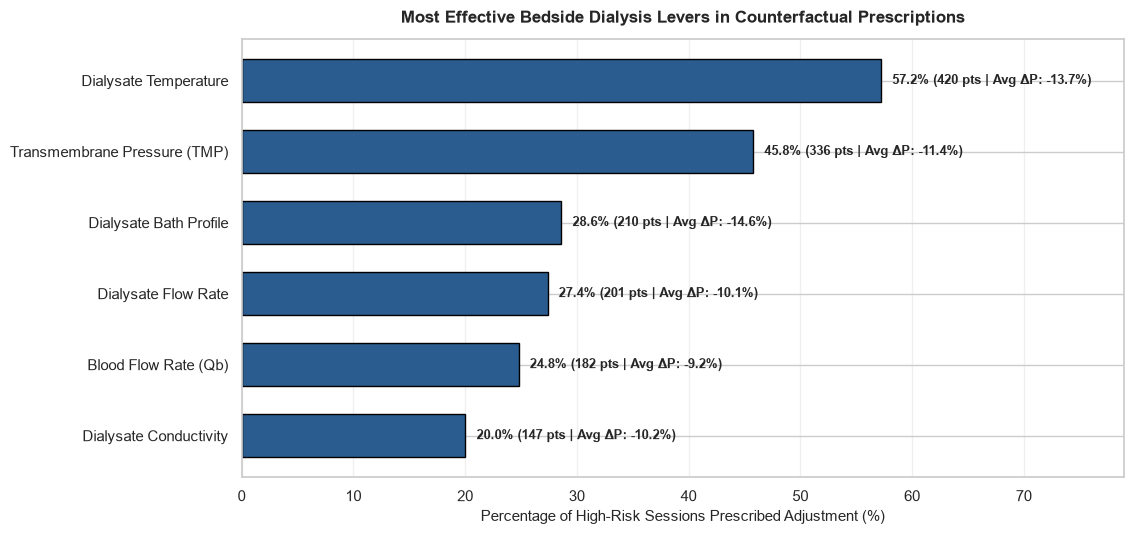

In [3]:
# ==============================================================================
# CELL 3: Actionable Bedside Dialysis Lever Effectiveness Ranking
# ==============================================================================
fig, ax = plt.subplots(figsize=(11.5, 5.5))
plot_df = lever_summary_df.sort_values(by="Usage_Rate_Pct", ascending=True)

bars = ax.barh(
    plot_df["Display_Name"],
    plot_df["Usage_Rate_Pct"],
    color="#2b5c8f",
    edgecolor="black",
    height=0.6
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 1.0,
        bar.get_y() + bar.get_height() / 2.0,
        f"{w:.1f}% ({int(row['Times_Prescribed'])} pts | Avg ΔP: -{row['Avg_Risk_Reduction']:.1%})",
        va="center", fontsize=9.5, fontweight="bold"
    )

ax.set_xlim(0, plot_df["Usage_Rate_Pct"].max() * 1.38)
ax.set_title(
    "Most Effective Bedside Dialysis Levers in Counterfactual Prescriptions",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.set_xlabel(
    "Percentage of High-Risk Sessions Prescribed Adjustment (%)", fontsize=10.5)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

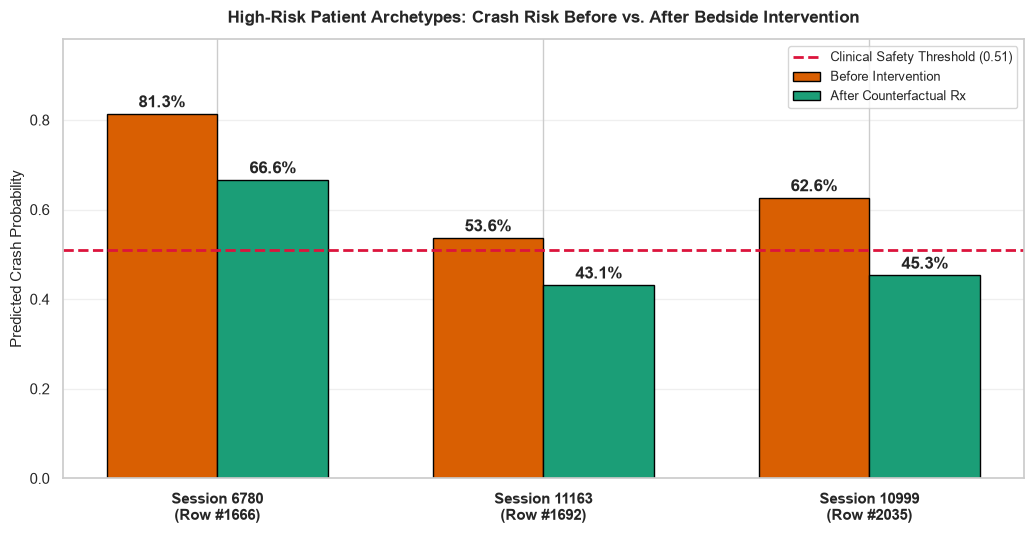

,Archetype,Session_ID,Holdout_Row,Before_Prob,After_Prob,Risk_Drop,Rescued,Dials_Changed,Clinical_Prescription
0,1. High-Confidence Caught Crash (True Positive),6780,1666,81.33%,66.58%,-14.74%,False,3,Transmembrane_Pressure: 0.027 -> 0.703 (↑0.676) | Dialysate_Temperature: 0.333 -> 1.000 (↑0.667) | Blood_Flow: 0.655 -> 0.828 (↑0.172)
1,2. Clinical Safety Rescued Crash (0.51 <= P < 0.57),11163,1692,53.63%,43.10%,-10.52%,True,1,Dialysate_Temperature: 0.333 -> 0.667 (↑0.333)
2,3. False Alarm Session (False Positive),10999,2035,62.58%,45.29%,-17.29%,True,1,Dialysate_Temperature: 0.333 -> 1.000 (↑0.667)


In [6]:
# ==============================================================================
# CELL 4: Personalized Bedside Prescriptions for Clinical Patient Archetypes
# ==============================================================================
target_keys = ["tp_caught", "tp_rescued", "fp_alarm"]
archetype_rows = []

for k in target_keys:
    pos_idx = archetypes[k]["pos_idx"]
    match = cf_df[cf_df["Holdout_Row"] == pos_idx].iloc[0]
    archetype_rows.append({
        "Archetype": archetypes[k]["label"],
        "Session_ID": int(match["Session_ID"]),
        "Holdout_Row": pos_idx,
        "Before_Prob": match["Original_Prob"],
        "After_Prob": match["Counterfactual_Prob"],
        "Risk_Drop": match["Risk_Reduction"],
        "Rescued": match["Rescued_Below_051"],
        "Dials_Changed": int(match["Levers_Changed"]),
        "Clinical_Prescription": match["Clinical_Prescription"],
    })

arch_df = pd.DataFrame(archetype_rows)

# Plot Before vs. After Bar Comparison
x = np.arange(len(arch_df))
width = 0.34
fig, ax = plt.subplots(figsize=(10.5, 5.5))

rects1 = ax.bar(
    x - width / 2, arch_df["Before_Prob"], width,
    label="Before Intervention", color="#d95f02", edgecolor="black"
)
rects2 = ax.bar(
    x + width / 2, arch_df["After_Prob"], width,
    label="After Counterfactual Rx", color="#1b9e77", edgecolor="black"
)
ax.axhline(
    clinical_thresh, color="crimson", linestyle="--", linewidth=2.0,
    label=f"Clinical Safety Threshold ({clinical_thresh:.2f})"
)

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width() / 2.0, h + 0.015,
            f"{h:.1%}", ha="center", fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width() / 2.0, h + 0.015,
            f"{h:.1%}", ha="center", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(
    [f"Session {r['Session_ID']}\n(Row #{r['Holdout_Row']})" for _,
     r in arch_df.iterrows()],
    fontsize=10.5, fontweight="bold"
)
ax.set_ylim(0, 0.98)
ax.set_ylabel("Predicted Crash Probability", fontsize=10.5)
ax.set_title(
    "High-Risk Patient Archetypes: Crash Risk Before vs. After Bedside Intervention",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.legend(loc="upper right", fontsize=9.5)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display full prescription table
arch_df.style.format({
    "Before_Prob": "{:.2%}",
    "After_Prob": "{:.2%}",
    "Risk_Drop": "-{:.2%}",
})